# Experiment No. 7 (Computer Laboratory – I BE AI&DS)

**Aim:** Interacting with Web APIs  
**Problem Statement:** Analyzing Weather Data from OpenWeatherMap API  
**Dataset:** Weather data retrieved from OpenWeatherMap API  

**Tasks to Perform:**
1. Register and obtain API key from OpenWeatherMap.
2. Interact with the OpenWeatherMap API using the API key to retrieve weather data for a specific location.
3. Extract relevant weather attributes such as temperature, humidity, wind speed, and precipitation from the API response.
4. Clean and preprocess the retrieved data, handling missing values or inconsistent formats.
5. Perform data modeling to analyze weather patterns (average temperature, maximum/minimum values, trends over time).
6. Visualize weather data using appropriate plots (line charts, bar plots, scatter plots).
7. Apply data aggregation techniques to summarize weather statistics by specific time periods (daily aggregations).
8. Incorporate geographical information to create geospatial visualizations across different locations.
9. Explore and visualize relationships between weather attributes (temperature, humidity, wind speed) using correlation plots and heatmaps.

In [ ]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# OpenWeatherMap API Key
API_KEY = "YOUR_API_KEY"
CITY = "Pune"

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Retrieve weather data from OpenWeatherMap API

url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    'q': CITY,
    'appid': API_KEY,
    'units': 'metric'
}

response = requests.get(url, params=params)

if response.status_code == 200:
    data = response.json()
    print("Weather data retrieved successfully!")
else:
    print("Error:", response.status_code, response.text)
    raise Exception("API request failed. Check your API key and city.")


# Extract weather attributes
weather_records = []

for item in data['list']:
    weather_records.append({
        'DateTime': item['dt_txt'],
        'Temperature': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'WindSpeed': item['wind']['speed'],
        'Pressure': item['main']['pressure'],
        'Precipitation': item.get('rain', {}).get('3h', 0),
        'Weather': item['weather'][0]['main']
    })

df = pd.DataFrame(weather_records)

print("\nWeather Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

Weather data retrieved successfully!

Weather Dataset:
              DateTime  Temperature  Humidity  WindSpeed  Pressure  \
0  2026-10-31 21:00:00        25.78        71       1.67      1014   
1  2026-11-01 00:00:00        25.39        74       1.88      1014   
2  2026-11-01 03:00:00        25.42        69       3.21      1015   
3  2026-11-01 06:00:00        31.74        50       3.63      1015   
4  2026-11-01 09:00:00        33.01        38       2.48      1011   

   Precipitation Weather  
0           0.37    Rain  
1           0.00  Clouds  
2           0.00  Clouds  
3           0.00  Clouds  
4           0.00  Clouds  

Dataset Shape: (40, 7)


In [3]:
# Convert DateTime into datetime format
df['DateTime'] = pd.to_datetime(df['DateTime'])

# Handle missing values
print("Missing Values:")
print(df.isnull().sum())

df['Precipitation'] = df['Precipitation'].fillna(0)

# Fill missing numerical values with column mean
numeric_cols = ['Temperature', 'Humidity', 'WindSpeed', 'Pressure']

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# Extract date and hour
df['Date'] = df['DateTime'].dt.date
df['Hour'] = df['DateTime'].dt.hour

print("\nCleaned Dataset:")
print(df.head())

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values:
DateTime         0
Temperature      0
Humidity         0
WindSpeed        0
Pressure         0
Precipitation    0
Weather          0
dtype: int64

Cleaned Dataset:
             DateTime  Temperature  Humidity  WindSpeed  Pressure  \
0 2026-10-31 21:00:00        25.78        71       1.67      1014   
1 2026-11-01 00:00:00        25.39        74       1.88      1014   
2 2026-11-01 03:00:00        25.42        69       3.21      1015   
3 2026-11-01 06:00:00        31.74        50       3.63      1015   
4 2026-11-01 09:00:00        33.01        38       2.48      1011   

   Precipitation Weather        Date  Hour  
0           0.37    Rain  2026-10-31    21  
1           0.00  Clouds  2026-11-01     0  
2           0.00  Clouds  2026-11-01     3  
3           0.00  Clouds  2026-11-01     6  
4           0.00  Clouds  2026-11-01     9  

Missing Values After Cleaning:
DateTime         0
Temperature      0
Humidity         0
WindSpeed        0
Pressure         0
Precipit

In [4]:
# Calculate weather statistics

print("Average Temperature:", df['Temperature'].mean())
print("Maximum Temperature:", df['Temperature'].max())
print("Minimum Temperature:", df['Temperature'].min())
print("Average Humidity:", df['Humidity'].mean())
print("Average Wind Speed:", df['WindSpeed'].mean())
print("Total Precipitation:", df['Precipitation'].sum())


# Daily weather aggregation
daily_summary = df.groupby('Date').agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'WindSpeed': 'mean',
    'Precipitation': 'sum'
})

print("\nDaily Weather Summary:")
print(daily_summary)

Average Temperature: 26.265750000000004
Maximum Temperature: 33.01
Minimum Temperature: 21.86
Average Humidity: 67.875
Average Wind Speed: 1.9100000000000001
Total Precipitation: 40.55

Daily Weather Summary:
            Temperature   Humidity  WindSpeed  Precipitation
Date                                                        
2026-10-31    25.780000  71.000000   1.670000           0.37
2026-11-01    27.613750  67.625000   2.171250           7.19
2026-11-02    25.528750  75.875000   2.086250          19.09
2026-11-03    25.085000  72.375000   1.513750          10.68
2026-11-04    26.291250  64.125000   1.597500           3.04
2026-11-05    26.957143  57.714286   2.254286           0.18


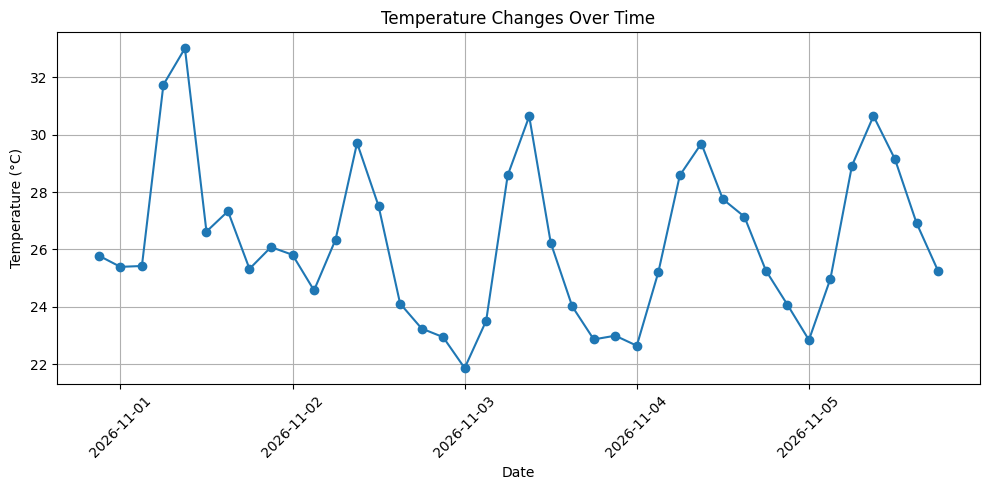

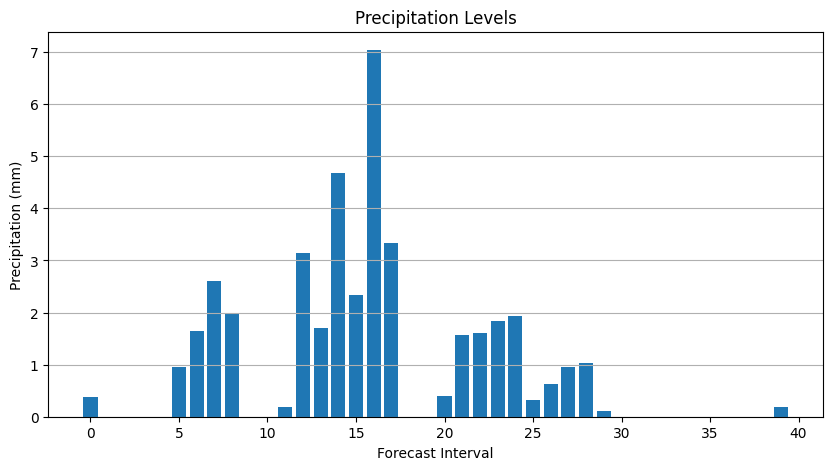

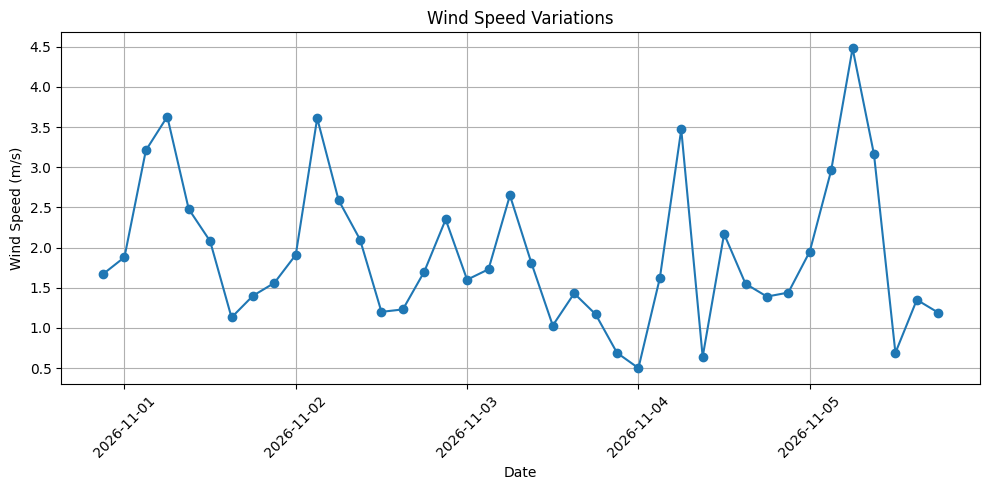

In [5]:
# Temperature Changes Over Time
plt.figure(figsize=(10, 5))

plt.plot(df['DateTime'], df['Temperature'], marker='o')

plt.title('Temperature Changes Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()


# Precipitation Visualization
plt.figure(figsize=(10, 5))

plt.bar(range(len(df)), df['Precipitation'])

plt.title('Precipitation Levels')
plt.xlabel('Forecast Interval')
plt.ylabel('Precipitation (mm)')
plt.grid(axis='y')
plt.show()


# Wind Speed Visualization
plt.figure(figsize=(10, 5))

plt.plot(df['DateTime'], df['WindSpeed'], marker='o')

plt.title('Wind Speed Variations')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

        City  Latitude  Longitude  Temperature
0       Pune   18.5196    73.8553        25.78
1     Mumbai   19.0144    72.8479        28.14
2      Delhi   28.6667    77.2167        19.49
3  Bangalore   12.9762    77.6033        21.24
4    Chennai   13.0878    80.2785        28.43


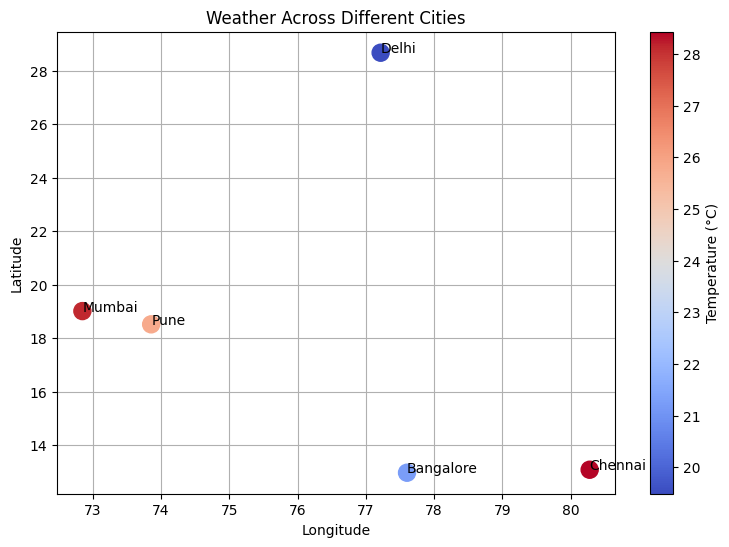

In [6]:
# Retrieve weather data for multiple cities

cities = ['Pune', 'Mumbai', 'Delhi', 'Bangalore', 'Chennai']

locations = []

for city in cities:

    params = {
        'q': city,
        'appid': API_KEY,
        'units': 'metric'
    }

    response = requests.get(url, params=params)

    if response.status_code == 200:
        city_data = response.json()

        locations.append({
            'City': city,
            'Latitude': city_data['city']['coord']['lat'],
            'Longitude': city_data['city']['coord']['lon'],
            'Temperature': city_data['list'][0]['main']['temp']
        })

geo_df = pd.DataFrame(locations)

print(geo_df)


# Plot geographical weather data
plt.figure(figsize=(9, 6))

plt.scatter(
    geo_df['Longitude'],
    geo_df['Latitude'],
    c=geo_df['Temperature'],
    cmap='coolwarm',
    s=150
)

for i, row in geo_df.iterrows():
    plt.annotate(
        row['City'],
        (row['Longitude'], row['Latitude'])
    )

plt.colorbar(label='Temperature (°C)')
plt.title('Weather Across Different Cities')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid()
plt.show()

Correlation Matrix:
               Temperature  Humidity  WindSpeed  Pressure  Precipitation
Temperature       1.000000 -0.882479   0.353451 -0.442274      -0.335506
Humidity         -0.882479  1.000000  -0.286475  0.390093       0.432361
WindSpeed         0.353451 -0.286475   1.000000  0.310220      -0.217977
Pressure         -0.442274  0.390093   0.310220  1.000000      -0.100735
Precipitation    -0.335506  0.432361  -0.217977 -0.100735       1.000000


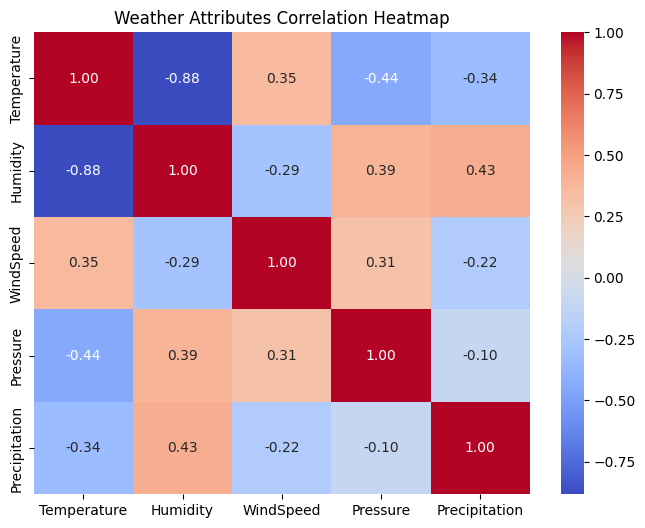

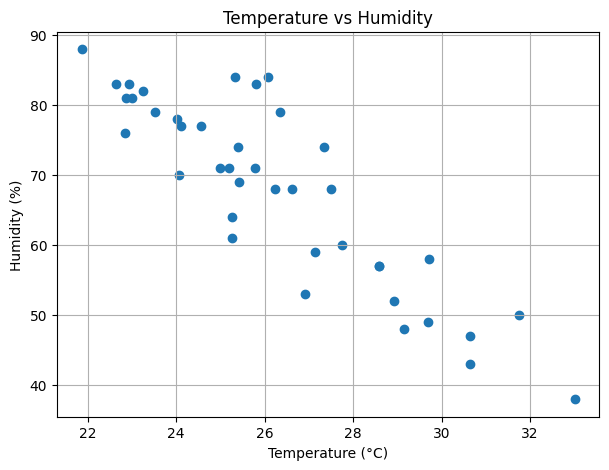

In [7]:
# Calculate correlation between weather attributes

corr = df[
    ['Temperature', 'Humidity', 'WindSpeed',
     'Pressure', 'Precipitation']
].corr()

print("Correlation Matrix:")
print(corr)


# Correlation Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Weather Attributes Correlation Heatmap')
plt.show()


# Temperature vs Humidity
plt.figure(figsize=(7, 5))

plt.scatter(df['Temperature'], df['Humidity'])

plt.title('Temperature vs Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.grid()
plt.show()